# India Daily Rainfall — Data Analysis for the BiLSTM / Transformer Forecasting Pipeline (v3)

**Dataset:** `india_weather_rainfall_data.xlsx` — daily Meteostat records, Jan 2015 – Feb 2025, weather stations across India
(temperature avg/min/max, wind speed, air pressure, rainfall, station, state, district, location, elevation, season).

**Purpose of this notebook:** document the data *exactly as the forecasting notebook uses it*
(`rainfall-bilstm-transformer`: next-day rainfall from the previous 30 days). It therefore follows the **same data lineup**:

| step | rule (identical to the model notebook) |
|---|---|
| 1. Period | keep **2021-01-02 →** only (`START_DATE`) — before that, rainfall / pressure / wind are mostly missing and not missing at random |
| 2. Cleaning | **delete every row with a missing value** (no imputation); delete rows with `max_temp > 50 °C` |
| 3. Station key | `station_id` = name + latitude + longitude + elevation (names are not unique) |
| 4. Split | **chronological**: train 2021-01-02 → 2023-03-31 · validation 2023-04-01 → 2024-03-31 · test 2024-04-01 → 2025-02-10 |
| 5. Features | 21 model inputs: weather, `rain_log`, station geometry, 9 neighbour / regional features, day-of-year sin/cos; scaler fitted on **train only** |
| 6. Windows | 30 consecutive days at one station → rainfall of the next day (`HORIZON = 1`) |

> **What changed compared with the previous analysis notebook**
> * The analysis now runs on the cleaned, split data the model sees (train / validation / test), not on a separate "rainfall panel" / "temperature panel".
> * Sections that do not help to document or explain the model were **removed**: station-count bars, fitted Gamma / Log-normal / Weibull / GPD models,
>   ridgeline plot, state box-plots and heat-maps, the 2015–2024 temperature decomposition / anomaly / heat-day plots, wet–dry-spell statistics,
>   Rx1day / Rx5day extremes and the periodogram.
> * Plots where **three variables belong together** are now 3-D (3-D histogram, 3-D bars, 3-D surface, 3-D scatter). Plots that are really a single curve or a
>   comparison of a few bars stay 2-D, because 3-D would only make them harder to read.

### Contents
1. Setup & configuration  2. Loading & audit  3. Cleaning  4. Chronological split  5. Features & windows
6. Rainfall target (distribution, intensity classes)  7. Spatial & seasonal structure  8. Time series
9. Relationships between model inputs and the target  10. Summary

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Setup & configuration
All values below are **copied from the model notebook** — change them there and here together.

In [2]:
import os, math, time, calendar, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import Axes3D            # noqa: F401  (registers the 3-D projection)
from sklearn.preprocessing import StandardScaler
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

# ------------------------- CONFIGURATION (identical to the model notebook) -------------------------
DATA_PATH   = "/content/drive/MyDrive/Fall'26/DeepLearning/Quiz_analysis/india_weather_rainfall_data.xlsx"   # None = search common places
CACHE_PATH  = "rainfall_raw_cache.pkl"      # same cache file as the model notebook (first run reads the slow .xlsx)

SEQ_LEN     = 30            # days of history fed to the models
HORIZON     = 1             # 1 = next-day rainfall
START_DATE  = "2021-01-02"  # before this date >65 % of rainfall / pressure / wind values are missing (not at random)
VAL_START   = "2023-04-01"  # train = START_DATE .. VAL_START-1 ; validation = one full year
TEST_START  = "2024-04-01"  # test  = TEST_START .. end of file
CONTEXT_FROM_PREVIOUS_SPLIT = True    # only the TARGET day must lie inside the split, the input window may reach back
RAIN_DAY_MM = 1.0           # a "rainy day" (classification-style metrics in the model notebook)
K_NEIGH     = 6             # nearest stations used for the neighbour features
CELL_DEG    = 3             # size (degrees) of the regional cells

SPLIT_NAMES = ["train", "val", "test"]
SPLIT_COL   = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green"}     # same colours as the model notebook
MONTHS      = [calendar.month_abbr[m] for m in range(1, 13)]
RAIN_C, TEMP_C, PRESS_C, WIND_C = "#2a6f97", "#c1121f", "#6a4c93", "#2a9d8f"
# India Meteorological Department (IMD) daily rainfall classes (mm/day)
IMD_BINS   = [0.1, 2.5, 15.6, 64.5, 115.6, 204.5, np.inf]
IMD_LABELS = ["Very light (0.1–2.4)", "Light (2.5–15.5)", "Moderate (15.6–64.4)",
              "Heavy (64.5–115.5)", "Very heavy (115.6–204.4)", "Extremely heavy (≥204.5)"]

## 2. Loading & audit
Reading the 970 k-row Excel file takes a couple of minutes, so the first run stores a cache next to the notebook.

In [3]:
def find_data_file():
    candidates = ([DATA_PATH] if DATA_PATH else []) + [
        "india_weather_rainfall_data.xlsx",
        "/content/india_weather_rainfall_data.xlsx",
        "/content/drive/MyDrive/india_weather_rainfall_data.xlsx",
        "/kaggle/working/india_weather_rainfall_data.xlsx",
        "/mnt/user-data/uploads/india_weather_rainfall_data.xlsx",
    ]
    for p in candidates:
        if p and os.path.exists(p):
            return p
    raise FileNotFoundError("Could not find the .xlsx - set DATA_PATH in the configuration cell.")

if os.path.exists(CACHE_PATH):
    raw = pd.read_pickle(CACHE_PATH)
    print("Loaded cached copy:", CACHE_PATH)
else:
    path = find_data_file()
    print("Reading", path, "(slow, please wait)...")
    t0 = time.time()
    raw = pd.read_excel(path, engine="openpyxl")
    raw.to_pickle(CACHE_PATH)
    print(f"Read in {time.time()-t0:.0f}s and cached to {CACHE_PATH}")

raw["date_of_record"] = pd.to_datetime(raw["date_of_record"])
d = raw["date_of_record"]
print(f"Rows x columns           : {raw.shape[0]:,} x {raw.shape[1]}")
print(f"Date range               : {d.min().date()} -> {d.max().date()}")
print(f"Globally sorted by date? : {bool(d.is_monotonic_increasing)}   (the file restarts at an early date for every new station -> backward jumps: {int((d.diff().dt.days < 0).sum())})")
print(f"Fully duplicated rows    : {int(raw.duplicated().sum())}")
miss = raw.isna().sum().to_frame("n_missing").assign(pct=lambda x: (100 * x.n_missing / len(raw)).round(1))
display(miss[miss.n_missing > 0])
raw.head()

Reading /content/drive/MyDrive/Fall'26/DeepLearning/Quiz_analysis/india_weather_rainfall_data.xlsx (slow, please wait)...
Read in 119s and cached to rainfall_raw_cache.pkl
Rows x columns           : 970,339 x 15
Date range               : 2015-01-01 -> 2025-02-10
Globally sorted by date? : False   (the file restarts at an early date for every new station -> backward jumps: 413)
Fully duplicated rows    : 0


,n_missing,pct
min_temp,43898,4.5
max_temp,110598,11.4
wind_speed,274444,28.3
air_pressure,304664,31.4
rainfall,257554,26.5


,date_of_record,month,season,station_name,state,district,avg_temp,min_temp,max_temp,wind_speed,air_pressure,elevation,latitude,longitude,rainfall
0,2021-01-02,January,Winter,Gulmarg,JK,Baramulla,-2.2,-6.6,-0.8,2.2,1020.0,2652,34.05,74.4,0.1
1,2021-01-03,January,Winter,Gulmarg,JK,Baramulla,-3.6,-4.6,-1.8,3.7,1019.5,2652,34.05,74.4,4.4
2,2021-01-04,January,Winter,Gulmarg,JK,Baramulla,-3.0,-4.5,-1.1,2.1,1022.0,2652,34.05,74.4,2.3
3,2021-01-05,January,Winter,Gulmarg,JK,Baramulla,-3.3,-5.1,-1.2,2.8,1015.6,2652,34.05,74.4,35.0
4,2021-01-06,January,Winter,Gulmarg,JK,Baramulla,-3.9,-8.3,-1.0,3.4,1015.3,2652,34.05,74.4,25.5


### Why the analysis starts on 2021-01-02
Missing values are **not random in time or season**. Before 2021 about two-thirds of the rainfall values (and most wind / pressure values) are missing, and the
rainfall that *is* recorded is concentrated in the wet months. Deleting incomplete rows would therefore keep mostly rainy days and bias every statistic and every model.
The model notebook solves this with `START_DATE`; the figure documents the reason.

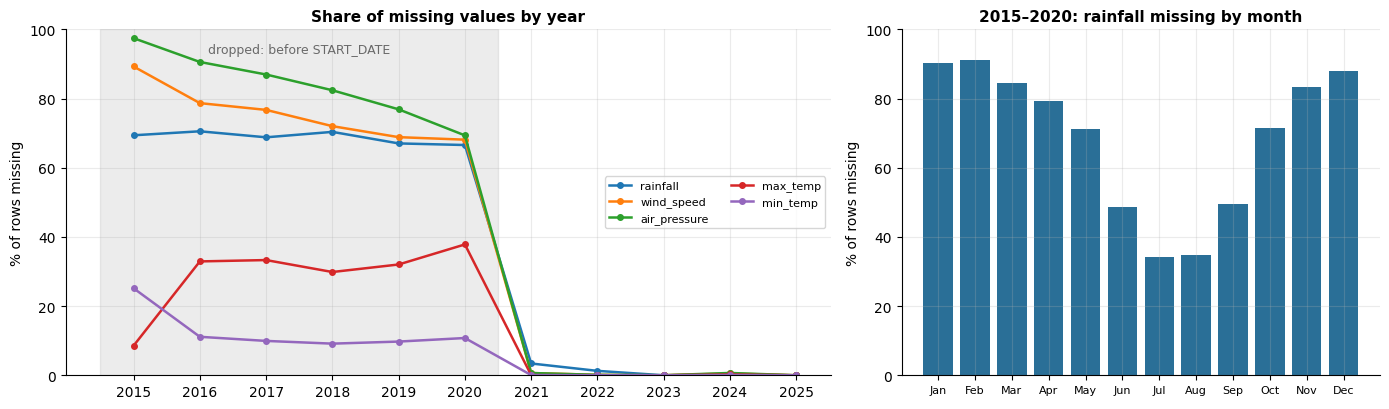

Share of zero-rain days among OBSERVED rainfall:  2015–2020 = 0.33   |   2021+ = 0.55
=> the 2015–2020 sample is biased towards rainy days; the model (and this analysis) start at START_DATE.


In [4]:
yr   = raw["date_of_record"].dt.year
cols = ["rainfall", "wind_speed", "air_pressure", "max_temp", "min_temp"]
miss_year = raw[cols].isna().groupby(yr).mean() * 100
early = raw[yr <= 2020]
miss_month = early["rainfall"].isna().groupby(early["date_of_record"].dt.month).mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
for c in cols:
    axes[0].plot(miss_year.index, miss_year[c], marker="o", ms=4, lw=1.8, label=c)
axes[0].axvspan(miss_year.index.min() - 0.5, 2020.5, color="grey", alpha=0.15)
axes[0].text(2017.5, 96, "dropped: before START_DATE", ha="center", va="top", color="dimgray", fontsize=9)
axes[0].set(title="Share of missing values by year", ylabel="% of rows missing", xticks=miss_year.index, ylim=(0, 100)); axes[0].legend(ncol=2, fontsize=8, loc="center right")
axes[1].bar(range(1, 13), miss_month.values, color=RAIN_C)
axes[1].set(title="2015–2020: rainfall missing by month", ylabel="% of rows missing", xticks=range(1, 13), xticklabels=MONTHS, ylim=(0, 100))
axes[1].tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

late = raw[yr >= 2021]
print(f"Share of zero-rain days among OBSERVED rainfall:  2015–2020 = {(early['rainfall'].dropna() == 0).mean():.2f}   |   2021+ = {(late['rainfall'].dropna() == 0).mean():.2f}")
print("=> the 2015–2020 sample is biased towards rainy days; the model (and this analysis) start at START_DATE.")

## 3. Cleaning — identical to the model notebook
* **Station key.** Eight station *names* belong to two different stations, so `station_id = name | lat | lon | elevation`.
* **Rows with any missing value are deleted** (no imputation, no missing-flags). Rows with `max_temp > 50 °C` are physically impossible and deleted too.
* Rainfall is never altered, and a missing rainfall is never read as 0 mm.

In [5]:
NEEDED    = ["avg_temp", "min_temp", "max_temp", "wind_speed", "air_pressure", "rainfall"]
USED_COLS = ["date_of_record", "station_name", "latitude", "longitude", "elevation"] + NEEDED

def make_station_id(x):
    return (x["station_name"].astype(str) + "|" + x["latitude"].round(4).astype(str) + "|"
            + x["longitude"].round(4).astype(str) + "|" + x["elevation"].astype(str))

raw["station_id"] = make_station_id(raw)
print("Unique station names                  :", raw["station_name"].nunique())
print("Unique station_ids                    :", raw["station_id"].nunique())
print("Duplicate (date, station_name) rows   :", int(raw.duplicated(["date_of_record", "station_name"]).sum()), " <- two different stations sharing one name")
print("Duplicate (date, station_id) rows     :", int(raw.duplicated(["date_of_record", "station_id"]).sum()), " <- the correct key (must be 0)")
assert not raw.duplicated(["date_of_record", "station_id"]).any()
multi = raw.groupby("station_name")["station_id"].nunique()
print("Names shared by >1 physical station   :", multi[multi > 1].index.tolist())

# ---- cleaning rules ----
nonfinite   = ~np.isfinite(raw[NEEDED].to_numpy(dtype="float64")).all(axis=1)
has_missing = raw[USED_COLS].isna().any(axis=1) | nonfinite
bad_range   = raw["max_temp"] > 50
in_period   = raw["date_of_record"] >= pd.Timestamp(START_DATE)

clean = raw.loc[~has_missing & ~bad_range & in_period].reset_index(drop=True)
assert clean[USED_COLS].notna().all().all() and np.isfinite(clean[NEEDED].to_numpy(dtype="float64")).all()

n0 = len(raw)
funnel = pd.DataFrame({"rows": [n0, -int((~in_period).sum()), -int((in_period & has_missing).sum()),
                                -int((in_period & ~has_missing & bad_range).sum()), len(clean)]},
                      index=["raw file", f"before START_DATE ({START_DATE})", "≥ 1 missing value (inside the period)",
                             "max_temp > 50 °C (inside the period)", "CLEAN data used by the model"])
funnel["% of raw rows"] = (100 * funnel["rows"].abs() / n0).round(1)
display(funnel)

yr_tab = pd.DataFrame({"raw rows": raw.groupby(raw["date_of_record"].dt.year).size(),
                       "clean rows": clean.groupby(clean["date_of_record"].dt.year).size()}).fillna(0).astype(int)
yr_tab["stations (clean)"] = clean.groupby(clean["date_of_record"].dt.year)["station_id"].nunique().reindex(yr_tab.index).fillna(0).astype(int)
display(yr_tab)

overview = pd.Series({
    "Distinct stations (clean data)": clean["station_id"].nunique(),
    "States / UTs": clean["state"].nunique(),
    "Districts": clean["district"].nunique(),
    "Elevation range (m)": f"{clean.elevation.min()} – {clean.elevation.max()}",
    "Latitude range": f"{clean.latitude.min():.1f} – {clean.latitude.max():.1f}",
    "Longitude range": f"{clean.longitude.min():.1f} – {clean.longitude.max():.1f}",
})
display(overview.to_frame("clean data"))
print("\nSummary statistics of the clean model variables:")
display(clean[NEEDED].describe().T.round(2))

Unique station names                  : 406
Unique station_ids                    : 414
Duplicate (date, station_name) rows   : 21703  <- two different stations sharing one name
Duplicate (date, station_id) rows     : 0  <- the correct key (must be 0)
Names shared by >1 physical station   : ['Agra', 'Akola', 'Car Nicobar', 'Jamshedpur', 'Madurai', 'Siliguri', 'Srinagar', 'Thiruvananthapuram']


,rows,% of raw rows
raw file,970339,100.0
before START_DATE (2021-01-02),-364879,37.6
≥ 1 missing value (inside the period),-8164,0.8
max_temp > 50 °C (inside the period),-2,0.0
CLEAN data used by the model,597294,61.6


,raw rows,clean rows,stations (clean)
date_of_record,,,
2015,44728,0,0
2016,61183,0,0
2017,61616,0,0
2018,63411,0,0
2019,66224,0,0
2020,67532,0,0
2021,141866,136667,406
2022,149392,147417,412
2023,149788,149781,413


,clean data
Distinct stations (clean data),414
States / UTs,32
Districts,314
Elevation range (m),0 – 2652
Latitude range,8.0 – 34.1
Longitude range,68.8 – 95.4



Summary statistics of the clean model variables:


,count,mean,std,min,25%,50%,75%,max
avg_temp,597294.0,25.23,5.44,-10.4,22.6,26.3,28.7,43.2
min_temp,597294.0,20.52,5.97,-18.5,17.0,22.2,25.0,36.6
max_temp,597294.0,30.82,5.47,-5.6,28.0,31.0,34.0,50.0
wind_speed,597294.0,9.62,5.06,0.0,6.2,8.5,11.8,66.6
air_pressure,597294.0,1009.45,5.28,982.4,1005.8,1009.8,1013.3,1036.5
rainfall,597294.0,4.16,11.81,0.0,0.0,0.0,2.8,485.9


## 4. Chronological split (train / validation / test)
The cleaned data is sorted by date and cut at fixed calendar dates, so that **train < validation < test in time** and nothing overlaps. Validation is exactly one full year (all seasons).

In [6]:
df = clean.sort_values(["date_of_record", "station_id"], kind="stable").reset_index(drop=True)
train_cut, val_cut = pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)
df["split_code"] = np.select([df["date_of_record"].values < train_cut, df["date_of_record"].values < val_cut], [0, 1], default=2)

summary = (df.groupby("split_code")
             .agg(rows=("rainfall", "size"), first_date=("date_of_record", "min"), last_date=("date_of_record", "max"),
                  stations=("station_id", "nunique"), mean_rain_mm=("rainfall", "mean"))
             .rename(index=dict(enumerate(SPLIT_NAMES))))
summary["row_share_%"] = (100 * summary["rows"] / len(df)).round(1)
display(summary)

mx = df.groupby("split_code")["date_of_record"].max(); mn = df.groupby("split_code")["date_of_record"].min()
assert mx[0] < mn[1] and mx[1] < mn[2], "splits overlap in time!"
print("OK: train < validation < test in time, no overlap.")

# per-station, date-ordered table used for windowing (stations contiguous, dates increasing)
daily = df.sort_values(["station_id", "date_of_record"], kind="stable").reset_index(drop=True)

,rows,first_date,last_date,stations,mean_rain_mm,row_share_%
split_code,,,,,,
train,321063,2021-01-02,2023-03-31,412,4.107763,53.8
val,150294,2023-04-01,2024-03-31,413,3.736071,25.2
test,125937,2024-04-01,2025-02-10,412,4.817660,21.1


OK: train < validation < test in time, no overlap.


**Figure — records per calendar month in each split (3-D bars).** Three things belong together here (month × split × number of records), which is why this one is 3-D.
It makes two properties of the split visible: the **test period contains no March at all and only a few February rows** (it ends on 10 Feb 2025),
and the training part has more January–March rows because those months occur in more than two years.

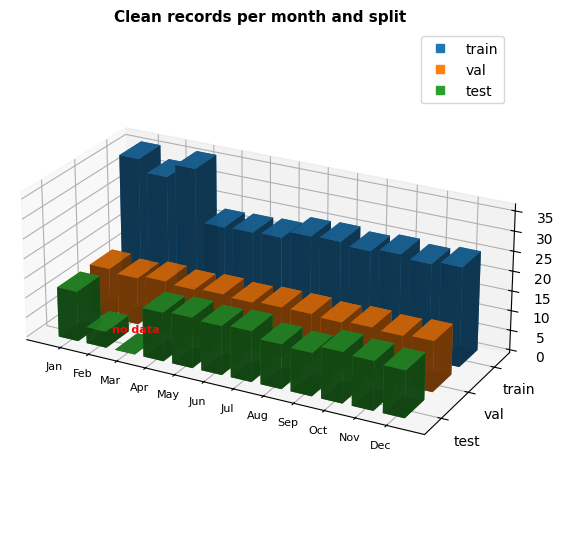

In [7]:
ct = (pd.crosstab(df["split_code"].map(dict(enumerate(SPLIT_NAMES))), df["date_of_record"].dt.month)
        .reindex(index=SPLIT_NAMES, columns=range(1, 13), fill_value=0))
fig = plt.figure(figsize=(12, 6.5)); ax = fig.add_subplot(projection="3d")
xx, yy = np.meshgrid(np.arange(12), np.arange(3))
zz = (ct.values / 1000.0)
cols_ = [SPLIT_COL[SPLIT_NAMES[i]] for i in yy.ravel()]
ax.bar3d(xx.ravel() - 0.35, yy.ravel() - 0.35, 0, 0.7, 0.7, zz.ravel(), color=cols_, shade=True, alpha=0.92)
for j in range(12):                                    # mark months that have no data at all
    for i in range(3):
        if ct.values[i, j] == 0:
            ax.text(j, i, 3.0, "no data", color="red", ha="center", fontsize=8, fontweight="bold")
ax.set_xticks(range(12)); ax.set_xticklabels(MONTHS, fontsize=8)
ax.set_yticks(range(3)); ax.set_yticklabels(SPLIT_NAMES); ax.set_ylim(2.6, -0.6)      # train (tallest bars) at the back
ax.set(zlabel="Clean station-days (thousand)", title="Clean records per month and split")
ax.view_init(elev=24, azim=-62); ax.set_box_aspect((2.2, 1, 0.8))
ax.legend(handles=[Line2D([0], [0], marker="s", ls="", color=SPLIT_COL[s], label=s) for s in SPLIT_NAMES], loc="upper right")
plt.tight_layout(); plt.show()

## 5. Features & sliding windows (as built in the model notebook)
The 21 model inputs are rebuilt with the **same code** so that the analysis below uses the same numbers the networks see:
`avg_temp, min_temp, max_temp, temp_range, wind_speed, air_pressure, rain_log, latitude, longitude, elevation`, nine neighbour / regional features
(`dp_own, nb_lr, nb_lrmax, nb_dp, nb_dT, nb_wind, reg_lr, nat_lr, nat_dp`) and `doy_sin, doy_cos`. The target is `log1p(rainfall)` of the next day.
`feat_raw` keeps the un-scaled values (for plots); `feat` / `X` are standardised with a scaler fitted on the **training rows only**.

In [8]:
WEATHER   = ["avg_temp", "min_temp", "max_temp", "wind_speed", "air_pressure"]
STATIC    = ["latitude", "longitude", "elevation"]
REG_COLS  = ["dp_own", "nb_lr", "nb_lrmax", "nb_dp", "nb_dT", "nb_wind", "reg_lr", "nat_lr", "nat_dp"]
CONT_COLS = ["avg_temp", "min_temp", "max_temp", "temp_range", "wind_speed", "air_pressure",
             "rain_log", "latitude", "longitude", "elevation"] + REG_COLS
CYC_COLS  = ["doy_sin", "doy_cos"]
FEATURES  = CONT_COLS + CYC_COLS
N_FEAT    = len(FEATURES)

# ---------------- neighbour / regional features (computed from the whole station network) ----------------
stations = raw.drop_duplicates("station_id").set_index("station_id")[["latitude", "longitude"]].sort_index()
ST_IDS   = stations.index.values;  N_ST = len(ST_IDS)
ST_POS   = {s: i for i, s in enumerate(ST_IDS)}
_xy      = np.c_[stations["latitude"].values, stations["longitude"].values * np.cos(np.deg2rad(stations["latitude"].values))]
_D       = ((_xy[:, None, :] - _xy[None, :, :]) ** 2).sum(-1); np.fill_diagonal(_D, 1e9)
NB       = np.argsort(_D, axis=1)[:, :K_NEIGH]
_cell    = (np.floor(stations["latitude"].values / CELL_DEG).astype(int).astype(str) + "_" +
            np.floor(stations["longitude"].values / CELL_DEG).astype(int).astype(str))
_cu, CELL_CODE = np.unique(_cell, return_inverse=True)
CELL_M   = np.eye(len(_cu))[CELL_CODE]

def regional_features(frame):
    """frame: RAW rows of many stations (NaN allowed); needs the day BEFORE the first wanted day (for 1-day changes)."""
    d0, d1 = frame["date_of_record"].min(), frame["date_of_record"].max()
    days = pd.date_range(d0, d1)
    def grid(col):
        g = frame.pivot(index="date_of_record", columns="station_id", values=col).reindex(index=days, columns=ST_IDS)
        return g.to_numpy(dtype="float64")
    lr   = np.log1p(np.clip(grid("rainfall"), 0, None))
    pres, avg, wind = grid("air_pressure"), grid("avg_temp"), grid("wind_speed")
    d1d  = lambda a: np.vstack([np.full((1, a.shape[1]), np.nan), np.diff(a, axis=0)])
    dp, dT = d1d(pres), d1d(avg)
    nb_mean = lambda a: np.nanmean(a[:, NB], axis=2)
    nb_max  = lambda a: np.nanmax(a[:, NB], axis=2)
    def cell_mean(a):
        m = ~np.isnan(a)
        with np.errstate(invalid="ignore", divide="ignore"):
            return ((np.where(m, a, 0.0) @ CELL_M) / (m.astype(float) @ CELL_M))[:, CELL_CODE]
    nat = lambda a: np.repeat(np.nanmean(a, axis=1, keepdims=True), a.shape[1], axis=1)
    G = {"dp_own": dp, "nb_lr": nb_mean(lr), "nb_lrmax": nb_max(lr), "nb_dp": nb_mean(dp), "nb_dT": nb_mean(dT),
         "nb_wind": nb_mean(wind), "reg_lr": cell_mean(lr), "nat_lr": nat(lr), "nat_dp": nat(dp)}
    ti = (frame["date_of_record"] - d0).dt.days.to_numpy()
    si = frame["station_id"].map(ST_POS).to_numpy()
    out = pd.DataFrame({k: v[ti, si] for k, v in G.items()}, index=frame.index)
    out["date_of_record"], out["station_id"] = frame["date_of_record"].values, frame["station_id"].values
    return out

raw_recent = raw[raw["date_of_record"] >= pd.Timestamp(START_DATE) - pd.Timedelta(days=1)]
reg_tbl = regional_features(raw_recent)
daily = daily.merge(reg_tbl[["date_of_record", "station_id"] + REG_COLS], on=["date_of_record", "station_id"], how="left")
REG_FILL = daily.loc[daily["split_code"] == 0, REG_COLS].median()                 # fill values from TRAIN only
daily[REG_COLS] = daily[REG_COLS].fillna(REG_FILL)

def make_features(dd):
    f = pd.DataFrame(index=dd.index)
    for c in WEATHER: f[c] = dd[c]
    f["temp_range"] = dd["max_temp"] - dd["min_temp"]
    f["rain_log"]   = np.log1p(dd["rainfall"].clip(lower=0))
    for c in STATIC:   f[c] = dd[c]
    for c in REG_COLS: f[c] = dd[c]
    doy = dd["date_of_record"].dt.dayofyear.values
    f["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    f["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    return f[FEATURES].astype("float32")

feat_raw   = make_features(daily)                          # un-scaled (physical units) - used for the plots below
feat       = feat_raw.copy()
train_rows = daily["split_code"].values == 0
scaler     = StandardScaler().fit(feat.loc[train_rows, CONT_COLS])      # fit on TRAIN only
feat[CONT_COLS] = scaler.transform(feat[CONT_COLS]).astype("float32")

X = feat[FEATURES].values.astype("float32")
Y = np.log1p(daily["rainfall"].values).astype("float32")             # target: log1p(rainfall); never missing
assert np.isfinite(X).all() and np.isfinite(Y).all()
print(f"Feature matrix: {X.shape} | features: {N_FEAT} | NaN/inf: none")
print("Features:", FEATURES)

Feature matrix: (597294, 21) | features: 21 | NaN/inf: none
Features: ['avg_temp', 'min_temp', 'max_temp', 'temp_range', 'wind_speed', 'air_pressure', 'rain_log', 'latitude', 'longitude', 'elevation', 'dp_own', 'nb_lr', 'nb_lrmax', 'nb_dp', 'nb_dT', 'nb_wind', 'reg_lr', 'nat_lr', 'nat_dp', 'doy_sin', 'doy_cos']


In [9]:
# ---------------- sliding windows: 30 consecutive days at ONE station -> next-day rainfall ----------------
L, H = SEQ_LEN, HORIZON
dates      = daily["date_of_record"].values
sid        = daily["station_id"].values
pos        = daily.groupby("station_id", sort=False).cumcount().values
split_arr  = daily["split_code"].values
j          = np.arange(len(daily))

ok = pos >= L - 1 + H                                                    # enough earlier rows in the same station
first_input = np.where(ok, j - H - L + 1, 0)
ok &= (dates - dates[first_input]) == np.timedelta64(L - 1 + H, "D")     # ...and they are consecutive calendar days
n_gap_removed = int((pos >= L - 1 + H).sum() - ok.sum())
if not CONTEXT_FROM_PREVIOUS_SPLIT:
    ok &= split_arr[first_input] == split_arr
tgt_idx = {name: j[ok & (split_arr == code)] for code, name in enumerate(SPLIT_NAMES)}
rain_mm = daily["rainfall"].values
y_mm    = {k: rain_mm[tgt_idx[k]] for k in SPLIT_NAMES}                  # target in mm, per split

for code_, k in enumerate(SPLIT_NAMES):                                  # same leakage checks as the model notebook
    t = tgt_idx[k]; first = t - H - L + 1
    assert (split_arr[t] == code_).all() and (sid[first] == sid[t]).all()
    assert (dates[first] + np.timedelta64(L - 1 + H, "D") == dates[t]).all()
assert dates[tgt_idx["train"]].max() < dates[tgt_idx["val"]].min() <= dates[tgt_idx["val"]].max() < dates[tgt_idx["test"]].min()
print(f"Rows that could be targets but are rejected because their window contains a removed day: {n_gap_removed:,}\n")

win = pd.DataFrame({k: {"windows": len(v), "target_from": pd.Timestamp(dates[v].min()).date(), "target_to": pd.Timestamp(dates[v].max()).date(),
                        "mean_rain_mm": float(rain_mm[v].mean())} for k, v in tgt_idx.items()}).T
display(win)

# counts reported by the model notebook for this configuration (a mismatch means the data or the configuration differs)
MODEL_NB_WINDOWS = {"train": 297046, "val": 150204, "test": 101540}
print("Same window counts as the model notebook:", {k: len(tgt_idx[k]) == v for k, v in MODEL_NB_WINDOWS.items()})

Rows that could be targets but are rejected because their window contains a removed day: 36,084



,windows,target_from,target_to,mean_rain_mm
train,297046,2021-02-01,2023-03-31,4.093804
val,150204,2023-04-01,2024-03-31,3.738026
test,101540,2024-04-01,2025-02-10,5.049185


Same window counts as the model notebook: {'train': True, 'val': True, 'test': True}


## 6. Rainfall target — what the models have to predict
All statistics in this section use the **target days of the model windows** (so exactly the samples the networks are trained, validated and tested on).
The target is highly **zero-inflated** (many dry days) and **heavy-tailed** (few very wet days) — this is why the models are trained on `log1p(rainfall)`
and why the model notebook reports rain / no-rain metrics (AUC, F1) next to RMSE.

In [10]:
def target_stats(v):
    rainy = v[v > 0]
    return {"windows": len(v), "mean (mm)": v.mean(), "dry day, 0 mm (%)": 100 * (v == 0).mean(),
            f"rainy day, ≥ {RAIN_DAY_MM:g} mm (%)": 100 * (v >= RAIN_DAY_MM).mean(),
            "median on rainy days (mm)": np.median(rainy), "95th pct (mm)": np.percentile(v, 95),
            "99th pct (mm)": np.percentile(v, 99), "max (mm)": v.max(),
            "skewness of rainy days": pd.Series(rainy).skew()}

tstats = pd.DataFrame({k: target_stats(y_mm[k]) for k in SPLIT_NAMES}).T
display(tstats.round(2))

# IMD intensity classes over all target days: how often, and how much of the total rainfall volume each class delivers
all_t = np.concatenate([y_mm[k] for k in SPLIT_NAMES])
cls = pd.cut(pd.Series(all_t).where(lambda s: s > 0), bins=IMD_BINS, labels=IMD_LABELS, right=False)
cls_n = cls.value_counts().reindex(IMD_LABELS)
vol   = pd.Series(all_t).groupby(cls).sum().reindex(IMD_LABELS)
cls_tbl = pd.DataFrame({"days": cls_n, "% of rainy days": 100 * cls_n / cls_n.sum(),
                        "% of all days": 100 * cls_n / len(all_t), "% of total rainfall volume": 100 * vol / vol.sum()})
display(cls_tbl.round(2))
print(f"Dry days (0 mm): {100*(all_t == 0).mean():.1f}% of all target days.")

,windows,mean (mm),"dry day, 0 mm (%)","rainy day, ≥ 1 mm (%)",median on rainy days (mm),95th pct (mm),99th pct (mm),max (mm),skewness of rainy days
train,297046.0,4.09,54.96,33.58,3.7,21.1,54.0,480.1,5.40
val,150204.0,3.74,57.27,30.97,3.1,20.1,51.3,472.2,5.55
test,101540.0,5.05,51.89,37.56,4.5,25.5,62.2,485.9,5.13


,days,% of rainy days,% of all days,% of total rainfall volume
Very light (0.1–2.4),104007,42.14,18.95,4.01
Light (2.5–15.5),99915,40.48,18.21,31.63
Moderate (15.6–64.4),39070,15.83,7.12,47.87
Heavy (64.5–115.5),3044,1.23,0.55,10.95
Very heavy (115.6–204.4),702,0.28,0.13,4.39
Extremely heavy (≥204.5),101,0.04,0.02,1.16


Dry days (0 mm): 55.0% of all target days.


**Figure — 3-D histogram: calendar month × rainfall amount × share of days.** Each bar is the percentage of all station-days of that month that fall into the given
rainfall class (dry days are not shown; they make up the rest to 100 %). It shows in one picture that (a) rainy days are rare outside the monsoon, (b) the
**light classes dominate every month**, and (c) the heavier classes (≥ 25 mm) are concentrated in the monsoon months (the printed share below gives the exact figure).

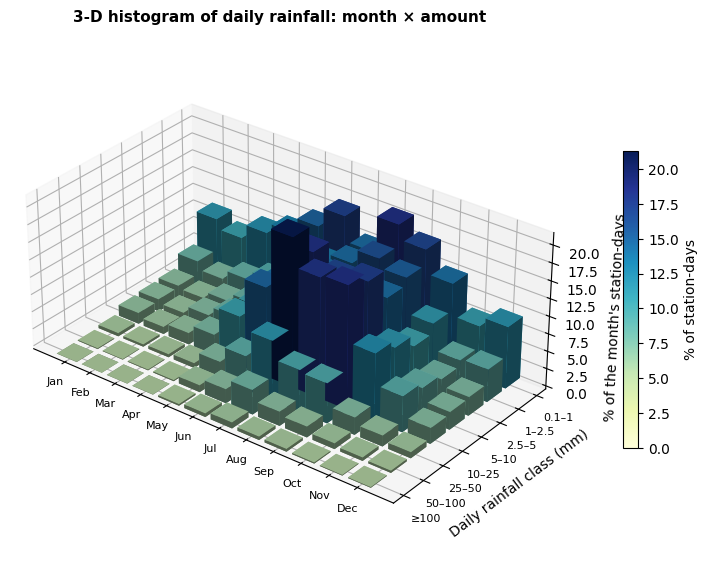

Station-days with ≥ 25 mm: 22,134; 73% of them fall in June–September (these 4 months hold 32% of all target days).


In [11]:
amt_edges  = [0.1, 1, 2.5, 5, 10, 25, 50, 100, np.inf]
amt_labels = ["0.1–1", "1–2.5", "2.5–5", "5–10", "10–25", "25–50", "50–100", "≥100"]
all_idx    = np.concatenate([tgt_idx[k] for k in SPLIT_NAMES])
t_month    = daily["date_of_record"].dt.month.values[all_idx]
t_amt      = pd.cut(pd.Series(rain_mm[all_idx]), bins=amt_edges, labels=amt_labels, right=False)
share = (pd.crosstab(t_amt, t_month, normalize=False).reindex(index=amt_labels, columns=range(1, 13), fill_value=0)
         .div(pd.Series(t_month).value_counts().sort_index(), axis=1) * 100)

fig = plt.figure(figsize=(12, 7)); ax = fig.add_subplot(projection="3d")
xx, yy = np.meshgrid(np.arange(12), np.arange(len(amt_labels)))
zz = share.values
norm = Normalize(0, zz.max()); colors = plt.get_cmap("YlGnBu")(0.25 + 0.75 * norm(zz.ravel()))
ax.bar3d(xx.ravel() - 0.4, yy.ravel() - 0.4, 0, 0.8, 0.8, zz.ravel(), color=colors, shade=True, edgecolor="none")
ax.set_xticks(range(12)); ax.set_xticklabels(MONTHS, fontsize=8)
ax.set_yticks(range(len(amt_labels))); ax.set_yticklabels(amt_labels, fontsize=8)
ax.set_ylim(len(amt_labels) - 0.5, -0.5)                      # light classes at the back, heavy classes in front
ax.set(xlabel="", ylabel="Daily rainfall class (mm)", zlabel="% of the month's station-days", title="3-D histogram of daily rainfall: month × amount")
ax.view_init(elev=30, azim=-52); ax.set_box_aspect((2.3, 1.3, 0.9))
sm = plt.cm.ScalarMappable(cmap=plt.get_cmap("YlGnBu"), norm=Normalize(0, zz.max())); sm.set_array([])
fig.colorbar(sm, ax=ax, shrink=0.55, pad=0.08, label="% of station-days")
plt.tight_layout(); plt.show()

heavy_m = t_month[rain_mm[all_idx] >= 25]
print(f"Station-days with ≥ 25 mm: {len(heavy_m):,}; {100*np.isin(heavy_m, [6, 7, 8, 9]).mean():.0f}% of them fall in June–September (these 4 months hold {100*np.isin(t_month, [6, 7, 8, 9]).mean():.0f}% of all target days).")

**Figure — does the target change between the splits?** Left: smoothed density of rainy-day amounts (log scale; a light jitter removes the 0.1 mm rounding steps).
Right: probability that a rainy day exceeds a given amount. The curves of train, validation and test lie close together, so the three splits describe the *same* rainfall regime;
what differs is *which part of the year* each split covers (see the 3-D bar figure above and the time series below): the test period runs April → 10 Feb, so its mean (higher) and the validation mean (a full year) are not directly comparable.

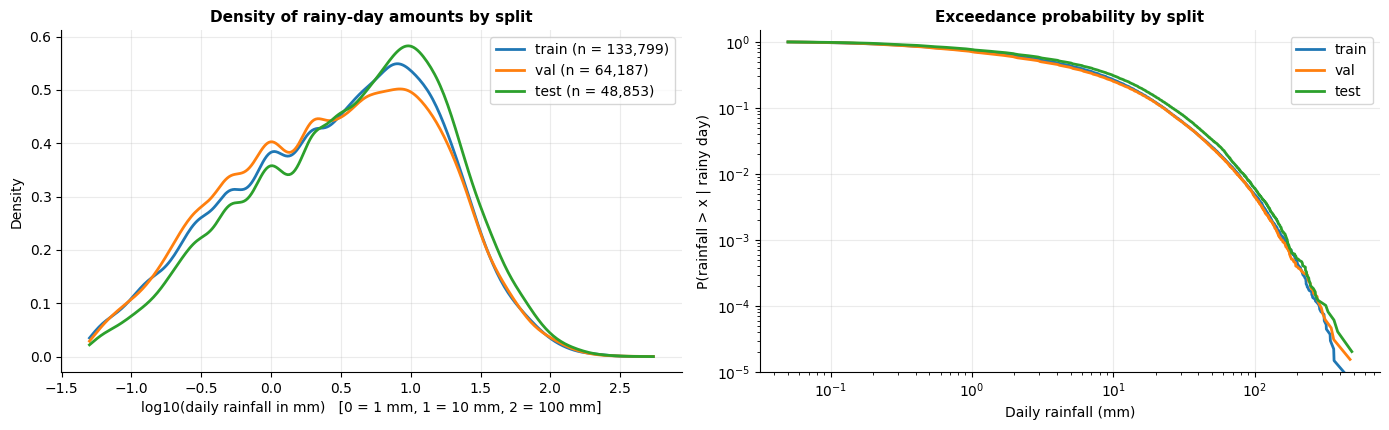

In [12]:
from scipy.stats import gaussian_kde
rng = np.random.default_rng(42)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
bins = np.linspace(-1.3, np.log10(max(v.max() for v in y_mm.values())) + 0.05, 46)
for k in SPLIT_NAMES:
    a = y_mm[k][y_mm[k] > 0]
    a = np.clip(a + rng.uniform(-0.05, 0.05, len(a)), 0.05, None)             # jitter: undo the 0.1 mm rounding
    la = np.log10(a); sub_ = rng.choice(la, size=min(40_000, len(la)), replace=False)
    xs_ = np.linspace(bins[0], bins[-1], 300)
    axes[0].plot(xs_, gaussian_kde(sub_, bw_method=0.12)(xs_), lw=2, color=SPLIT_COL[k], label=f"{k} (n = {len(a):,})")
    xs = np.sort(a); axes[1].plot(xs, np.arange(len(xs), 0, -1) / len(xs), lw=2, color=SPLIT_COL[k], label=k)
axes[0].set(xlabel="log10(daily rainfall in mm)   [0 = 1 mm, 1 = 10 mm, 2 = 100 mm]", ylabel="Density", title="Density of rainy-day amounts by split"); axes[0].legend()
axes[1].set(xscale="log", yscale="log", ylim=(1e-5, 1.5), xlabel="Daily rainfall (mm)", ylabel="P(rainfall > x | rainy day)", title="Exceedance probability by split"); axes[1].legend()
plt.tight_layout(); plt.show()

## 7. Spatial and seasonal structure
Stations differ enormously in how much it rains (location, elevation) and rain follows a strong seasonal cycle, which is why the models receive
`latitude, longitude, elevation, doy_sin, doy_cos` and the neighbour / regional rainfall features.

### 7a. Where does it rain? — 3-D station map
Longitude, latitude and **elevation** span a natural 3-D space, so each station is a point in that space, coloured by its mean annual rainfall and sized by its wet-day frequency.
(The grey dots on the floor are the same stations seen from above, i.e. the usual map.)

414 stations in the clean data (annual rainfall = mean daily rainfall × 365.25, from the clean rows of 2021–2025).


,station,state,annual_mm,wet_day_freq_%,elev
station_id,,,,,
Mahabaleshwar|17.9333|73.6667|1384,Mahabaleshwar,MH,5969.1,41.2,1384
Cherrapunji|25.25|91.7333|1312,Cherrapunji,ML,4516.9,57.3,1312
Agumbe|13.5|75.0833|658,Agumbe,KA,4181.5,62.5,658
Dhubri Rupsi|26.15|89.9167|35,Dhubri Rupsi,AS,4092.9,44.9,35
Gangtok|27.3333|88.6167|1756,Gangtok,SK,4072.1,63.1,1756
Mangalore / Bajpe|12.9167|74.8833|102,Mangalore / Bajpe,KA,3998.2,46.1,102
Honavar|14.2833|74.45|8,Honavar,KA,3942.1,42.6,8
Pasighat|28.1|95.3833|155,Pasighat,AR,3931.2,44.4,155


,count,mean,std,min,25%,50%,75%,max
annual_mm,414.0,1519.9,798.8,266.4,1041.9,1289.1,1679.0,5969.1
wet_day_freq_%,414.0,33.5,12.7,7.5,24.9,31.2,39.7,72.0
elev,414.0,311.1,429.8,0.0,15.0,153.5,455.2,2652.0
lat,414.0,20.9,6.3,8.0,16.0,21.8,25.7,34.1
lon,414.0,79.6,5.9,68.8,75.7,78.1,82.7,95.4


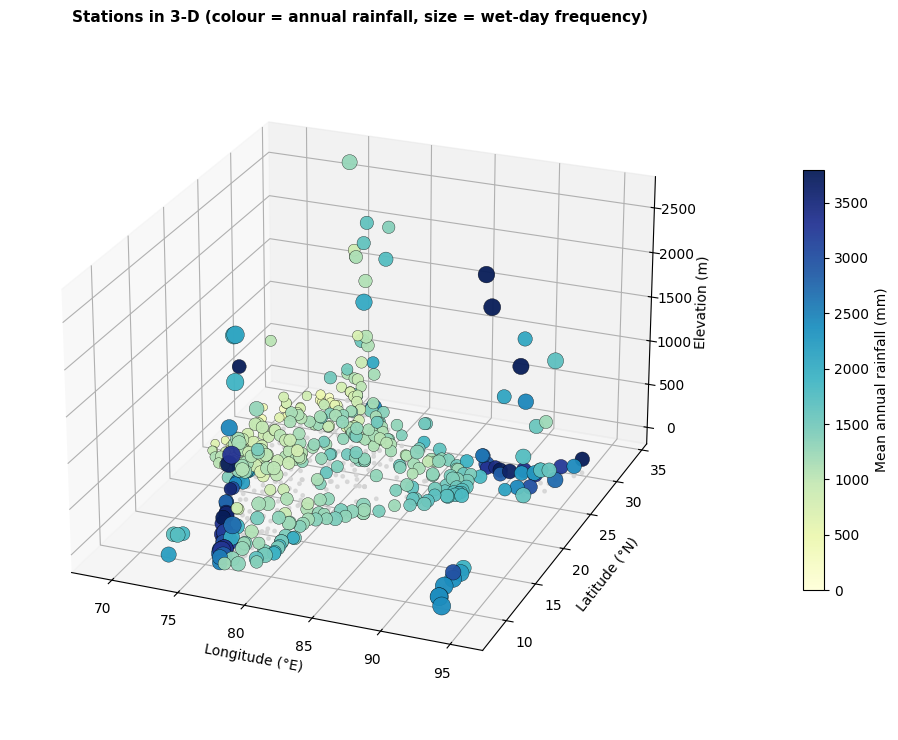

In [13]:
g = daily.groupby("station_id")
stn = pd.DataFrame({"station": g["station_name"].first(), "state": g["state"].first(), "lat": g["latitude"].first(), "lon": g["longitude"].first(),
                    "elev": g["elevation"].first(), "days": g.size(), "mean_daily_mm": g["rainfall"].mean(),
                    "wet_day_freq_%": 100 * (daily["rainfall"] >= RAIN_DAY_MM).groupby(daily["station_id"]).mean()})
stn["annual_mm"] = stn["mean_daily_mm"] * 365.25
print(f"{len(stn)} stations in the clean data (annual rainfall = mean daily rainfall × 365.25, from the clean rows of 2021–2025).")
display(stn.sort_values("annual_mm", ascending=False).head(8)[["station", "state", "annual_mm", "wet_day_freq_%", "elev"]].round(1))
display(stn[["annual_mm", "wet_day_freq_%", "elev", "lat", "lon"]].describe().T.round(1))

fig = plt.figure(figsize=(12, 7.5)); ax = fig.add_subplot(projection="3d")
vmax = stn["annual_mm"].quantile(0.98)
ax.scatter(stn["lon"], stn["lat"], np.zeros(len(stn)), s=6, color="lightgrey", alpha=0.8)              # shadow on the floor
sc = ax.scatter(stn["lon"], stn["lat"], stn["elev"], c=stn["annual_mm"], cmap="YlGnBu", vmin=0, vmax=vmax,
                s=12 + 2.2 * stn["wet_day_freq_%"], edgecolor="k", linewidth=0.25, alpha=0.95, depthshade=False)
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)", zlabel="Elevation (m)", title="Stations in 3-D (colour = annual rainfall, size = wet-day frequency)")
ax.view_init(elev=24, azim=-68); ax.set_box_aspect((1, 1.15, 0.7))
fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.08, label="Mean annual rainfall (mm)")
plt.tight_layout(); plt.show()

### 7b. When does it rain, and where? — 3-D rainfall surface (latitude band × month)
Mean daily rainfall of every 2° latitude band in every month. The ridge shows the monsoon moving across latitudes; the contour map on the floor shows the same data from above.

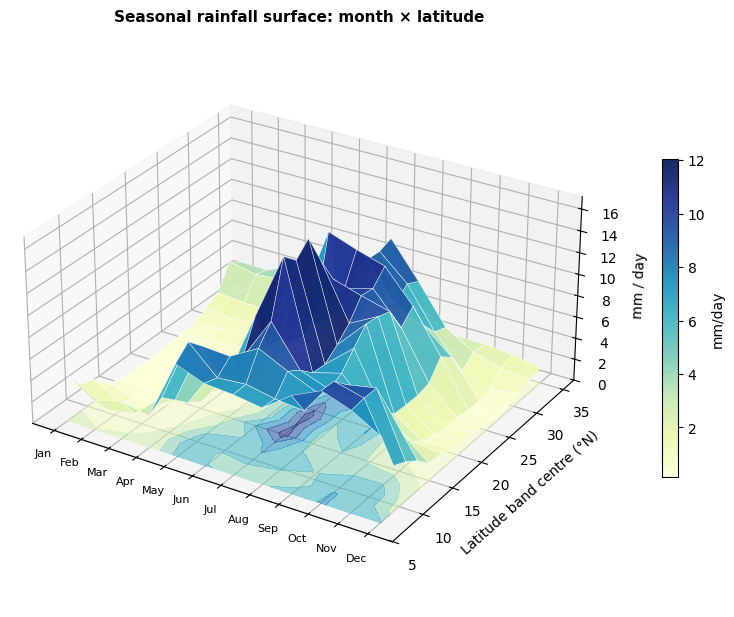

In [14]:
lat_edges = np.arange(np.floor(daily["latitude"].min() / 2) * 2, np.ceil(daily["latitude"].max() / 2) * 2 + 2, 2.0)
band = pd.cut(daily["latitude"], lat_edges, labels=lat_edges[:-1] + 1.0)
surf = daily.assign(band=band.astype(float), m=daily["date_of_record"].dt.month).groupby(["band", "m"])["rainfall"].agg(["mean", "size"])
Z = surf["mean"].unstack().reindex(columns=range(1, 13))
N = surf["size"].unstack().reindex(columns=range(1, 13))
Z = Z.where(N >= 100)                                                     # hide cells with too few station-days
Z = Z.interpolate(axis=1, limit_direction="both").dropna(how="all")       # fill the rare thin cells from neighbouring months
Xg, Yg = np.meshgrid(np.arange(1, 13), Z.index.values)

fig = plt.figure(figsize=(12, 7.5)); ax = fig.add_subplot(projection="3d")
surf_p = ax.plot_surface(Xg, Yg, Z.values, cmap="YlGnBu", edgecolor="white", linewidth=0.3, alpha=0.95, rstride=1, cstride=1)
ax.contourf(Xg, Yg, Z.values, zdir="z", offset=0, cmap="YlGnBu", alpha=0.55)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(MONTHS, fontsize=8)
ax.set(ylabel="Latitude band centre (°N)", zlabel="mm / day", title="Seasonal rainfall surface: month × latitude")
ax.set_zlim(0, np.nanmax(Z.values) * 1.05); ax.view_init(elev=28, azim=-58); ax.set_box_aspect((1.6, 1.4, 0.8))
fig.colorbar(surf_p, ax=ax, shrink=0.55, pad=0.08, label="mm/day")
plt.tight_layout(); plt.show()

## 8. Time series
### 8a. National series with the train / validation / test periods
Mean daily rainfall over all stations that have a complete (clean) row on that day, and the number of such stations. Dips and gaps are days on which few or no stations had a complete row (all variables present); they are printed below the figure. The colour bands are the three splits.

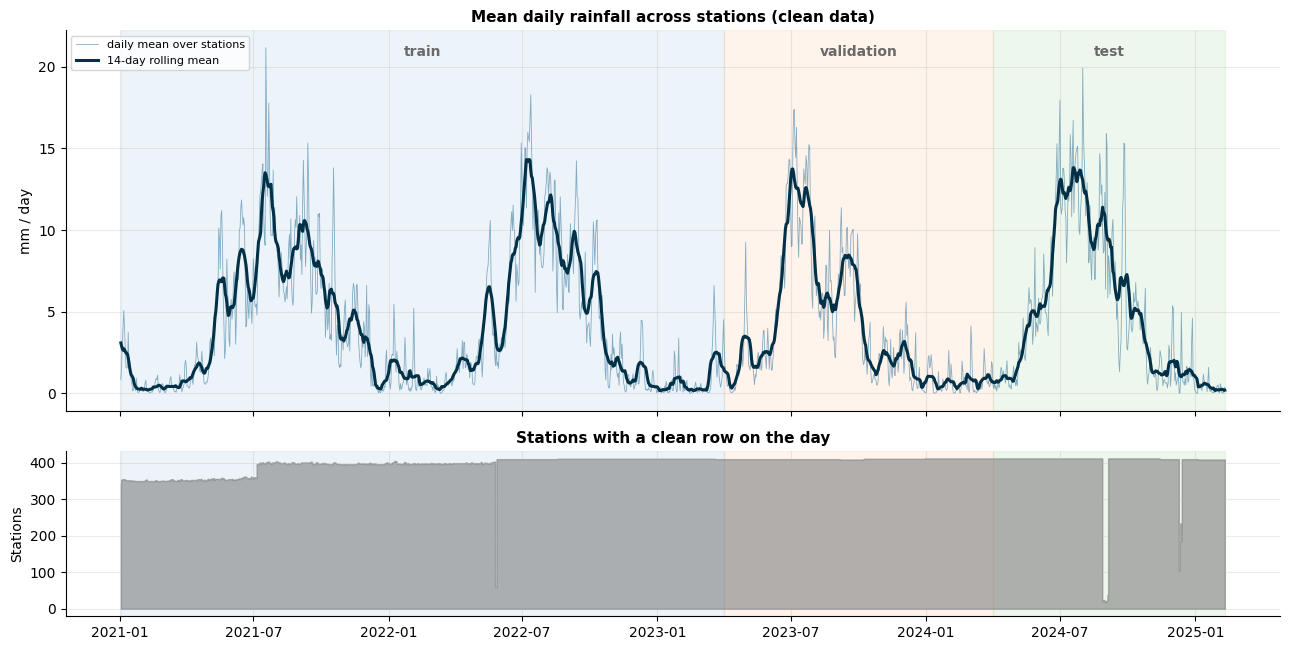

Days with fewer than half of the usual 410 stations (or none):


,from,to,days
1,2022-05-26,2022-05-27,2
2,2024-08-28,2024-09-04,8
3,2024-12-10,2024-12-11,2
4,2024-12-13,2024-12-13,1


In [15]:
nat = daily.groupby("date_of_record").agg(rain=("rainfall", "mean"), n=("rainfall", "size"))
full = nat.reindex(pd.date_range(nat.index.min(), nat.index.max()))
t0_, t1_, t2_, t3_ = pd.Timestamp(START_DATE), train_cut, val_cut, full.index.max()

fig, axes = plt.subplots(2, 1, figsize=(13, 6.6), sharex=True, gridspec_kw={"height_ratios": [2.3, 1]})
for ax in axes:
    for a, b, k in [(t0_, t1_, "train"), (t1_, t2_, "val"), (t2_, t3_, "test")]:
        ax.axvspan(a, b, color=SPLIT_COL[k], alpha=0.08)
axes[0].plot(full.index, full["rain"], lw=0.6, color=RAIN_C, alpha=0.55, label="daily mean over stations")
axes[0].plot(full["rain"].rolling(14, center=True, min_periods=7).mean(), lw=2.2, color="#023047", label="14-day rolling mean")
for a, b, k in [(t0_, t1_, "train"), (t1_, t2_, "validation"), (t2_, t3_, "test")]:
    axes[0].text(a + (b - a) / 2, axes[0].get_ylim()[1] * 0.93, k, ha="center", fontsize=10, fontweight="bold", color="dimgray")
axes[0].set(ylabel="mm / day", title="Mean daily rainfall across stations (clean data)"); axes[0].legend(loc="upper left", fontsize=8)
axes[1].fill_between(full.index, full["n"], color="grey", alpha=0.6, step="mid")
axes[1].set(ylabel="Stations", title="Stations with a clean row on the day")
plt.tight_layout(); plt.show()

low = full.index[(full["n"].fillna(0) < 0.5 * full["n"].median())]
if len(low):
    ls = pd.Series(low); blk = (ls.diff().dt.days != 1).cumsum()
    print(f"Days with fewer than half of the usual {int(full['n'].median())} stations (or none):")
    display(ls.groupby(blk).agg(["min", "max", "size"]).rename(columns={"min": "from", "max": "to", "size": "days"}))

### 8b. Seasonal cycle of the model inputs
Monthly mean of rainfall and of the three weather variables used as inputs (all clean station-days of 2021–2025). The smooth annual cycle is what `doy_sin` / `doy_cos` encode.

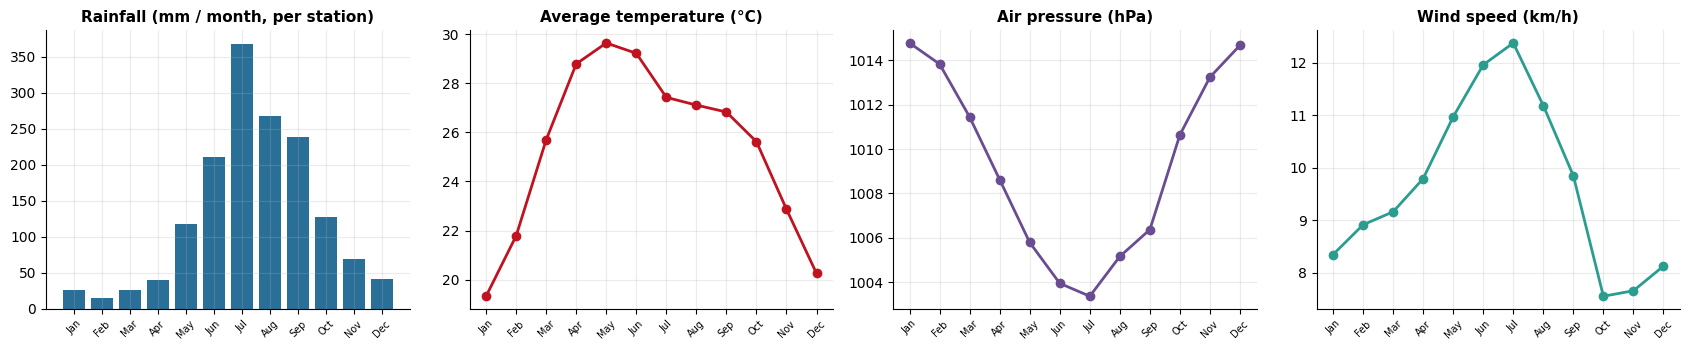

In [16]:
mm_ = daily.assign(m=daily["date_of_record"].dt.month).groupby("m").agg(rain=("rainfall", "mean"), temp=("avg_temp", "mean"),
                                                                       pressure=("air_pressure", "mean"), wind=("wind_speed", "mean"))
mm_["rain_month"] = mm_["rain"] * np.array([calendar.monthrange(2023, m)[1] for m in mm_.index])
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
axes[0].bar(MONTHS, mm_["rain_month"], color=RAIN_C); axes[0].set_title("Rainfall (mm / month, per station)")
for ax, col, title, c in zip(axes[1:], ["temp", "pressure", "wind"], ["Average temperature (°C)", "Air pressure (hPa)", "Wind speed (km/h)"], [TEMP_C, PRESS_C, WIND_C]):
    ax.plot(MONTHS, mm_[col], marker="o", color=c, lw=2); ax.set_title(title)
for ax in axes: ax.tick_params(axis="x", labelsize=7, rotation=45)
plt.tight_layout(); plt.show()

## 9. Model inputs versus the target
### 9a. Correlations (training windows)
Features are taken on the **last input day** (day *t*) of each training window and compared with the next-day target `log1p(rainfall)`.
Left: Spearman correlation between all 21 features (strongly related features, e.g. avg / min / max temperature or the rainfall features, carry overlapping information).
Right: Spearman ρ of each feature with the target, coloured by feature group.

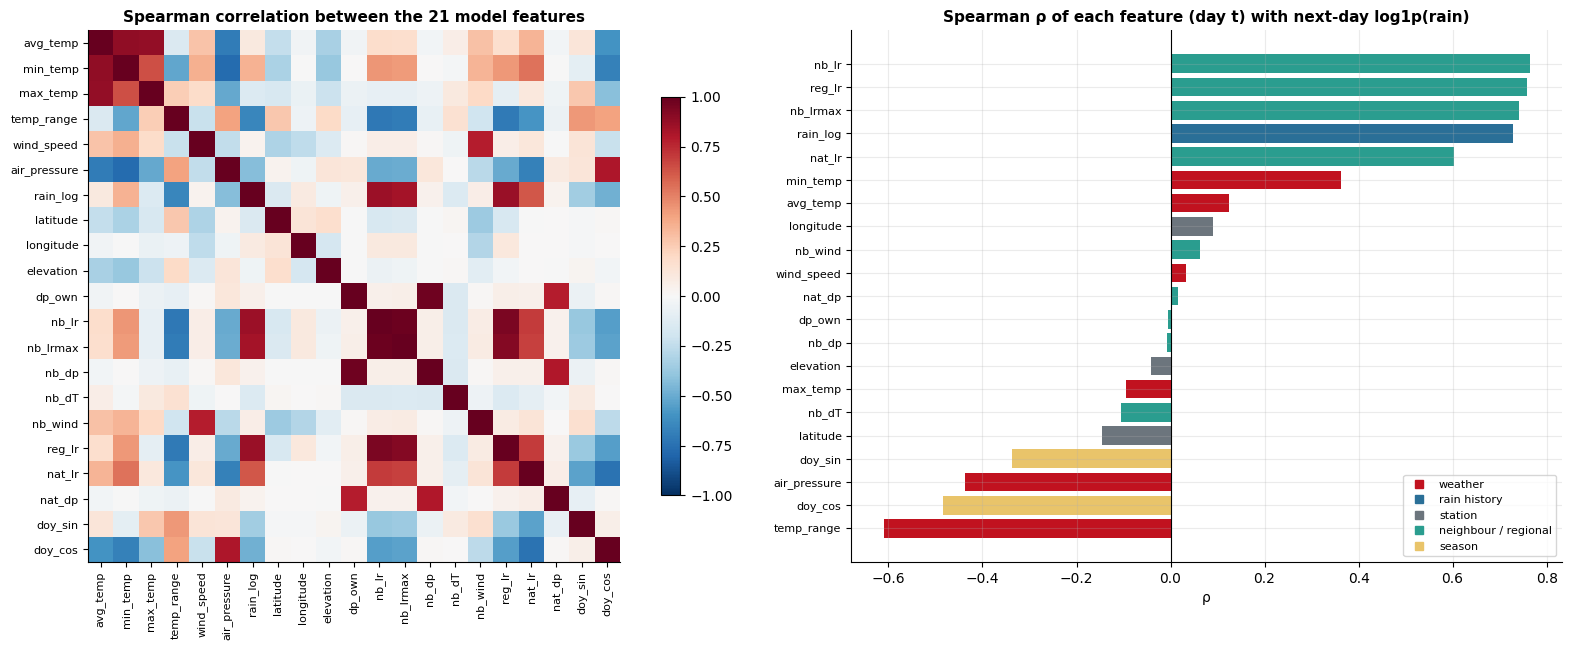

Strongest features: nb_lr (+0.76), reg_lr (+0.76), nb_lrmax (+0.74), rain_log (+0.73), temp_range (-0.61)

Mean of the standardised inputs per split (0 = training mean; in training-σ units):


,avg_temp,min_temp,max_temp,temp_range,wind_speed,air_pressure,rain_log,latitude,longitude,elevation,dp_own,nb_lr,nb_lrmax,nb_dp,nb_dT,nb_wind,reg_lr,nat_lr,nat_dp
train,-0.01,-0.00,-0.00,0.00,-0.00,0.02,-0.00,-0.00,-0.0,0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.01,0.00,0.00,0.00
val,0.09,0.09,0.10,0.00,0.39,0.14,-0.05,0.03,0.0,-0.03,0.00,-0.06,-0.03,0.01,0.00,0.49,-0.06,-0.10,0.01
test,0.31,0.34,0.28,-0.12,0.44,-0.31,0.10,0.03,-0.0,-0.03,-0.01,0.11,0.14,-0.01,-0.03,0.55,0.12,0.18,-0.02


In [17]:
tr = tgt_idx["train"]; last = tr - HORIZON
samp = np.random.default_rng(0).choice(len(tr), size=min(150_000, len(tr)), replace=False)
Xtr  = feat_raw.values[last[samp]]
ytr  = Y[tr[samp]]
rho_t = pd.Series([spearmanr(Xtr[:, i], ytr)[0] for i in range(N_FEAT)], index=FEATURES)
corr  = pd.DataFrame(Xtr, columns=FEATURES).corr(method="spearman")

GROUP = {**{c: "weather" for c in ["avg_temp", "min_temp", "max_temp", "temp_range", "wind_speed", "air_pressure"]},
         "rain_log": "rain history", **{c: "station" for c in STATIC}, **{c: "neighbour / regional" for c in REG_COLS}, **{c: "season" for c in CYC_COLS}}
GCOL  = {"weather": "#c1121f", "rain history": "#2a6f97", "station": "#6c757d", "neighbour / regional": "#2a9d8f", "season": "#e9c46a"}

fig, axes = plt.subplots(1, 2, figsize=(17, 6.6), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(N_FEAT)); axes[0].set_xticklabels(FEATURES, rotation=90, fontsize=8)
axes[0].set_yticks(range(N_FEAT)); axes[0].set_yticklabels(FEATURES, fontsize=8); axes[0].grid(False)
axes[0].set_title("Spearman correlation between the 21 model features"); fig.colorbar(im, ax=axes[0], shrink=0.75)
o = rho_t.sort_values()
axes[1].barh(o.index, o.values, color=[GCOL[GROUP[c]] for c in o.index]); axes[1].axvline(0, color="black", lw=0.8)
axes[1].set(title="Spearman ρ of each feature (day t) with next-day log1p(rain)", xlabel="ρ"); axes[1].tick_params(axis="y", labelsize=8)
axes[1].legend(handles=[Line2D([0], [0], marker="s", ls="", color=c, label=n) for n, c in GCOL.items()], loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

print("Strongest features:", ", ".join(f"{c} ({rho_t[c]:+.2f})" for c in rho_t.abs().sort_values(ascending=False).index[:5]))

# how far do validation / test inputs drift from the training distribution? (mean of the standardised features on the last input day)
drift = pd.DataFrame({k: X[tgt_idx[k] - HORIZON].mean(axis=0) for k in SPLIT_NAMES}, index=FEATURES)
print("\nMean of the standardised inputs per split (0 = training mean; in training-σ units):")
display(drift.loc[CONT_COLS].round(2).T)

### 9b. Persistence and neighbour signal — 3-D probability surface
Probability that **tomorrow is a rainy day** (≥ 1 mm) as a function of **today's rainfall at the station** and **today's rainfall at its 6 nearest stations**
(`nb_lr`, mean of `log1p(mm)`). Two inputs and one outcome — a natural 3-D surface. The rise along both axes is why the model gets the rain history *and* the neighbour features.
(Training windows only; cells with fewer than 300 samples are interpolated.)

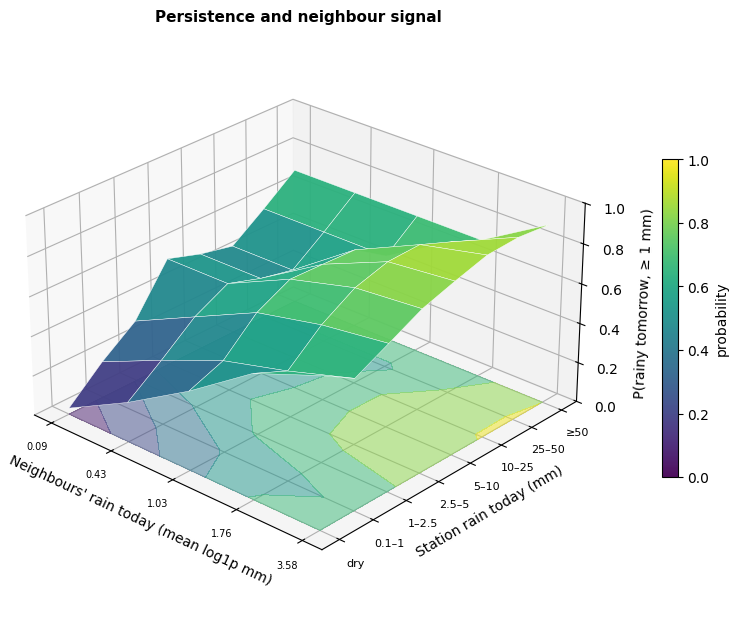

Overall P(rainy tomorrow) in the training windows: 0.34
  after a dry day at the station: 0.07   |   after a rainy day (≥ 1 mm): 0.76


In [18]:
own_edges = [0, 0.1, 1, 2.5, 5, 10, 25, 50, np.inf]
own_lab   = ["dry", "0.1–1", "1–2.5", "2.5–5", "5–10", "10–25", "25–50", "≥50"]
own  = pd.cut(pd.Series(rain_mm[last]), bins=own_edges, labels=range(len(own_lab)), right=False).astype(int).values
nbv  = feat_raw["nb_lr"].values[last]
nb_e = np.unique(np.quantile(nbv, np.linspace(0, 1, 9)));  nb_e[0] -= 1e-6; nb_e[-1] += 1e-6
nb_b = pd.cut(pd.Series(nbv), bins=nb_e, labels=False).astype(int).values
wet_next = (rain_mm[tr] >= RAIN_DAY_MM).astype(float)

tab = pd.DataFrame({"own": own, "nb": nb_b, "wet": wet_next}).groupby(["own", "nb"])["wet"].agg(["mean", "size"])
P  = tab["mean"].unstack().reindex(index=range(len(own_lab)), columns=range(len(nb_e) - 1))
Nn = tab["size"].unstack().reindex(index=range(len(own_lab)), columns=range(len(nb_e) - 1))
P  = P.where(Nn >= 300).interpolate(axis=1, limit_direction="both").interpolate(axis=0, limit_direction="both")
nb_mid = 0.5 * (nb_e[1:] + nb_e[:-1])
Xg, Yg = np.meshgrid(np.arange(P.shape[1]), np.arange(P.shape[0]))

fig = plt.figure(figsize=(12, 7.5)); ax = fig.add_subplot(projection="3d")
sp = ax.plot_surface(Xg, Yg, P.values, cmap="viridis", edgecolor="white", linewidth=0.3, vmin=0, vmax=1, alpha=0.95)
ax.contourf(Xg, Yg, P.values, zdir="z", offset=0, cmap="viridis", alpha=0.5, vmin=0, vmax=1)
ax.set_xticks(range(P.shape[1])); ax.set_xticklabels([f"{v:.2f}" for v in nb_mid], fontsize=7)
ax.set_yticks(range(len(own_lab))); ax.set_yticklabels(own_lab, fontsize=8)
ax.set(xlabel="Neighbours' rain today (mean log1p mm)", ylabel="Station rain today (mm)", zlabel="P(rainy tomorrow, ≥ 1 mm)",
       title="Persistence and neighbour signal", zlim=(0, 1))
ax.view_init(elev=27, azim=-48); ax.set_box_aspect((1.4, 1.4, 0.8))
fig.colorbar(sp, ax=ax, shrink=0.55, pad=0.08, label="probability")
plt.tight_layout(); plt.show()
print(f"Overall P(rainy tomorrow) in the training windows: {wet_next.mean():.2f}")
print(f"  after a dry day at the station: {wet_next[own == 0].mean():.2f}   |   after a rainy day (≥ 1 mm): {wet_next[own >= 2].mean():.2f}")

## 10. Summary
The cell below prints the headline numbers of this run, so it stays correct if the data or the configuration changes.

In [19]:
dry_all  = 100 * (all_t == 0).mean(); wet_all = 100 * (all_t >= RAIN_DAY_MM).mean()
heavy_vol = cls_tbl["% of total rainfall volume"].iloc[3:].sum()
wettest  = stn.groupby("state")["annual_mm"].median().sort_values(ascending=False)
wettest  = wettest[stn.groupby("state").size().reindex(wettest.index) >= 3]
print(f"""
DATA & CLEANING (same rules as the model notebook)
 • Raw file: {n0:,} station-days, {raw.station_id.nunique()} stations, {d.min():%b %Y} – {d.max():%b %Y}. Rainfall is missing for {raw.rainfall.isna().mean()*100:.0f}% of all rows
   ({early.rainfall.isna().mean()*100:.0f}% in 2015–2020 versus {late.rainfall.isna().mean()*100:.1f}% from 2021).
 • Clean data (from {START_DATE}, no missing / impossible values): {len(clean):,} rows = {100*len(clean)/n0:.1f}% of the file, {clean.station_id.nunique()} stations in {clean.state.nunique()} states / UTs.

SPLIT & WINDOWS
 • train: {len(tgt_idx['train']):,} windows | validation: {len(tgt_idx['val']):,} | test: {len(tgt_idx['test']):,}  ({SEQ_LEN}-day input → day t+{HORIZON}).
 • Mean target rainfall: train {y_mm['train'].mean():.2f} mm, validation {y_mm['val'].mean():.2f} mm, test {y_mm['test'].mean():.2f} mm — the test period (April → 10 Feb) is wetter and contains no March.

RAINFALL TARGET
 • {dry_all:.0f}% of target days are dry, {wet_all:.0f}% are rainy days (≥ {RAIN_DAY_MM:g} mm). Rainy-day amounts: median {np.median(all_t[all_t > 0]):.1f} mm, mean {all_t[all_t > 0].mean():.1f} mm, skewness {pd.Series(all_t[all_t > 0]).skew():.1f}.
 • Heavy-or-worse days (≥ 64.5 mm) are {100*(all_t >= 64.5).mean():.2f}% of days but deliver {heavy_vol:.0f}% of the total rainfall volume.
 • Mean annual rainfall over stations: {stn.annual_mm.mean():,.0f} mm (median {stn.annual_mm.median():,.0f}); wettest state/UT with ≥ 3 stations: {wettest.index[0]} ({wettest.iloc[0]:,.0f} mm), driest: {wettest.index[-1]} ({wettest.iloc[-1]:,.0f} mm).
 • Wettest month on average: {MONTHS[int(mm_.rain_month.idxmax()) - 1]} ({mm_.rain_month.max():.0f} mm); driest: {MONTHS[int(mm_.rain_month.idxmin()) - 1]} ({mm_.rain_month.min():.0f} mm).

PREDICTABILITY
 • Strongest single features (Spearman ρ with next-day log1p rain): {", ".join(f"{c} ({rho_t[c]:+.2f})" for c in rho_t.abs().sort_values(ascending=False).index[:3])}.
 • P(rainy tomorrow) is {wet_next[own >= 2].mean():.2f} after a rainy day versus {wet_next[own == 0].mean():.2f} after a dry day at the station.
""")


DATA & CLEANING (same rules as the model notebook)
 • Raw file: 970,339 station-days, 414 stations, Jan 2015 – Feb 2025. Rainfall is missing for 27% of all rows
   (69% in 2015–2020 versus 1.2% from 2021).
 • Clean data (from 2021-01-02, no missing / impossible values): 597,294 rows = 61.6% of the file, 414 stations in 32 states / UTs.

SPLIT & WINDOWS
 • train: 297,046 windows | validation: 150,204 | test: 101,540  (30-day input → day t+1).
 • Mean target rainfall: train 4.09 mm, validation 3.74 mm, test 5.05 mm — the test period (April → 10 Feb) is wetter and contains no March.

RAINFALL TARGET
 • 55% of target days are dry, 34% are rainy days (≥ 1 mm). Rainy-day amounts: median 3.7 mm, mean 9.3 mm, skewness 5.4.
 • Heavy-or-worse days (≥ 64.5 mm) are 0.70% of days but deliver 16% of the total rainfall volume.
 • Mean annual rainfall over stations: 1,520 mm (median 1,289); wettest state/UT with ≥ 3 stations: KL (3,000 mm), driest: HR (692 mm).
 • Wettest month on average: Jul (368 m

### What this means for the model (notes consistent with the model notebook)
* **Keep `START_DATE = 2021-01-02` and delete incomplete rows.** The 2015–2020 rainfall is too sparse and seasonally biased to learn from; after START_DATE the deletion removes only a small share of rows,
  but a window is only usable if all 30 input days and the target day exist, so some targets are lost (printed in section 5).
* **Use the chronological split, never a random one.** Neighbouring days are strongly correlated; random splits would leak. Because the splits cover different months
  (the test period has no March), compare models **on the same split** and read the absolute test numbers with that in mind.
* **Rainfall is zero-inflated and heavy-tailed** → train on `log1p(rainfall)`, evaluate in mm, and report rain / no-rain metrics (AUC, F1) next to RMSE / R².
  The back-transform `expm1` under-predicts the mean in mm, which is why the model notebook fits a calibration factor on the validation set.
* **The strongest signal is persistence and the neighbourhood** (own `rain_log`, `nb_lr`, `nb_lrmax`, `reg_lr`, `nat_lr`, all ρ ≈ 0.6–0.8); the diurnal temperature range, air pressure and the season terms are the next group (|ρ| ≈ 0.3–0.6),
  while wind, the pressure / temperature tendencies and elevation are weak on their own. Several inputs are strongly redundant (avg / min / max temperature; `nb_lr` / `nb_lrmax` / `reg_lr`; `air_pressure` / `doy_cos`), so a small network is enough.
* **Keep `station_id` consistent** (name + coordinates + elevation) and never fill a missing rainfall with 0 mm.
* **Licence:** CC BY-NC 4.0 — non-commercial use with attribution to Meteostat.